# Visual Diagnostics and Stationarity Testing

**Chapter 9 | Section 9.1**

**Docker image**: `ml4t`

Before a series can be modelled it has to be characterised. This notebook works
through the diagnostics that decide what kind of temporal object a price series is:
eyeballing it, testing whether its statistical properties hold still, measuring how
much of today it can predict about tomorrow, and turning those tests into features
that are recomputed as the sample rolls forward.

**Learning objectives**

- Read a four-panel diagnostic view of a price series and say what each panel rules in
  or out: a trend, clustered volatility, or tails heavier than a normal distribution.
- Decide whether a series can be modelled as-is by running two tests whose null
  hypotheses point in opposite directions, and reading them together.
- Measure whether the past of a series predicts its own future, and whether the past
  of its *squared* values predicts the size of future moves.
- Recompute those tests on a moving window so that "is this series well behaved" becomes
  a column that changes over time rather than one answer for the whole sample.

**Book reference**

Chapter 9, Section 9.1 (Diagnostics and stationarity features).

**Prerequisites**

None. This is the starting point for Chapter 9. The transforms that follow from these
diagnostics are in `02_structural_breaks` and `03_fractional_differencing`.

In [6]:
from utils import ML4T_DATA_PATH

p = ML4T_DATA_PATH / "macro" / "fred_macro.parquet"
print("读取位置：", p)
print("文件存在：", p.exists())

读取位置： /Users/selinayan/machine-learning-for-trading/data/macro/fred_macro.parquet
文件存在： True


## Setup

In [7]:
"""Visual Diagnostics and Stationarity Testing - the diagnostic workflow."""

import warnings
from datetime import datetime

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display
from ml4t.diagnostic.evaluation.autocorrelation import analyze_autocorrelation
from ml4t.diagnostic.evaluation.distribution import analyze_distribution
from ml4t.diagnostic.evaluation.stationarity import analyze_stationarity
from ml4t.diagnostic.evaluation.volatility import arch_lm_test
from ml4t.diagnostic.logging import LogLevel, configure_logging
from scipy.stats import norm, probplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

from data import load_etfs, load_macro
from utils.style import COLORS, FIGSIZE, show_with_alt

# A KPSS p-value is looked up in a published table, and a statistic beyond the ends of
# that table raises this warning on every call. The p-value the test returns already
# reports the saturation, and the section below reads it, so silence this one by name.
warnings.filterwarnings(
    "ignore",
    message="The test statistic is outside of the range of p-values",
    category=InterpolationWarning,
)
# Importing ml4t.diagnostic installs INFO log handlers; keep the output to results.
configure_logging(LogLevel.WARNING)

In [8]:
START_DATE = "2000-01-01"
END_DATE = "2024-12-31"
ROLLING_WINDOW = 252
ROLLING_STEP = 5

## The two series, and why these two

The diagnostics need a series that trends and a series that does not, so that the tests
have something to distinguish. SPY, the exchange-traded fund tracking the S&P 500,
supplies the first: its price drifts upward over two decades, so its average level in
one year says little about its average level in the next. The CBOE volatility index
(VIX) supplies the second: it measures the option market's expectation of near-term
volatility, spikes in a crisis, and comes back to a level in the teens afterwards, so
its long-run average is a number a model can use.

`START_DATE` and `END_DATE` bound the sessions every test in this notebook may read.
The ETF panel's SPY history opens in 2006, so the requested start binds only the VIX
series and the two are tested on different samples. The table below gives each series
its own span, and each test result carries the observation count it was computed from.

In [9]:
etfs = load_etfs(symbols=["SPY"])
spy = etfs.select(["timestamp", "close"]).rename({"close": "value"}).sort("timestamp")

macro = load_macro()
vix = (
    macro.select(["timestamp", "vixcls"]).drop_nulls().rename({"vixcls": "value"}).sort("timestamp")
)

START = datetime.strptime(START_DATE, "%Y-%m-%d")
END = datetime.strptime(END_DATE, "%Y-%m-%d")
spy = spy.filter((pl.col("timestamp") >= START) & (pl.col("timestamp") <= END))
vix = vix.filter((pl.col("timestamp") >= START) & (pl.col("timestamp") <= END))

spy = spy.with_columns(returns=pl.col("value").pct_change() * 100).drop_nulls()

spy_pd = spy.to_pandas().set_index("timestamp")
vix_pd = vix.to_pandas().set_index("timestamp")
returns = spy_pd["returns"]

In [10]:
coverage = pd.DataFrame(
    [
        {
            "series": name,
            "unit": unit,
            "observations": len(series),
            "first session": series.index.min().date(),
            "last session": series.index.max().date(),
        }
        for name, unit, series in [
            ("SPY close", "US dollars", spy_pd["value"]),
            ("SPY daily return", "percent", returns),
            ("VIX level", "annualized percent", vix_pd["value"]),
        ]
    ]
)
display(coverage)

,series,unit,observations,first session,last session
0,SPY close,US dollars,4780,2006-01-04,2024-12-31
1,SPY daily return,percent,4780,2006-01-04,2024-12-31
2,VIX level,annualized percent,9130,2000-01-03,2024-12-31


## Four panels before any test

Every formal test below answers a question that these four panels have already raised.
The price panel shows whether the level wanders; the return panel shows whether large
moves arrive in bursts rather than independently; the VIX panel shows a series that
repeatedly returns to the same neighbourhood; the histogram shows how far the return
distribution departs from the bell curve drawn by a normal distribution with the same
mean and standard deviation.

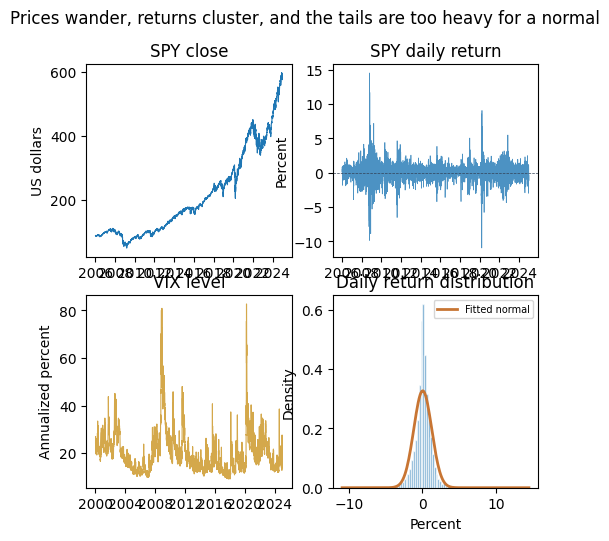

In [11]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE["dashboard_2x2"])

ax = axes[0, 0]
ax.plot(spy_pd.index, spy_pd["value"].values, linewidth=0.8)
ax.set_title("SPY close")
ax.set_ylabel("US dollars")

ax = axes[0, 1]
ax.plot(returns.index, returns.values, linewidth=0.5, alpha=0.8)
ax.axhline(0, color=COLORS["neutral"], linestyle="--", linewidth=0.5)
ax.set_title("SPY daily return")
ax.set_ylabel("Percent")

ax = axes[1, 0]
ax.plot(vix_pd.index, vix_pd["value"].values, linewidth=0.8, color=COLORS["amber"])
ax.set_title("VIX level")
ax.set_ylabel("Annualized percent")

ax = axes[1, 1]
ax.hist(returns.values, bins=100, density=True, alpha=0.7, edgecolor="white")
grid = np.linspace(returns.min(), returns.max(), 200)
ax.plot(
    grid,
    norm.pdf(grid, returns.mean(), returns.std()),
    color=COLORS["copper"],
    linewidth=2,
    label="Fitted normal",
)
ax.set_title("Daily return distribution")
ax.set_xlabel("Percent")
ax.set_ylabel("Density")
ax.legend(fontsize=7)

fig.suptitle("Prices wander, returns cluster, and the tails are too heavy for a normal")
show_with_alt(
    fig,
    "Four panels. Top left: the SPY closing price drifts upward with deep drawdowns. "
    "Top right: daily returns oscillate around zero with visible bursts of large moves. "
    "Bottom left: the VIX spikes and returns to the teens. Bottom right: a histogram of "
    "daily returns is more peaked than the fitted normal curve and has heavier tails.",
)

## Stationarity: two tests, opposite nulls

A series is **stationary** when its statistical properties do not depend on where in
the sample you look: the mean, the variance and the autocorrelations are the same in
the first half as in the second. A model fitted on one period only carries over to
another if this holds, which is why it is the first thing to test.

The specific failure to look for in a price series is a **unit root**: today's value is
yesterday's value plus a shock that never decays, so the level has no long-run average
to return to and shocks accumulate forever. A random walk is the canonical example.

Two tests are used together because each has a different null hypothesis, and a test
only ever gives evidence against its null:

| Test | Null hypothesis | Rejecting it means |
|:--|:--|:--|
| Augmented Dickey-Fuller (ADF) | the series has a unit root | there is no unit root |
| Kwiatkowski-Phillips-Schmidt-Shin (KPSS) | the series is stationary around a constant level | the level is not constant |

Reading them jointly resolves the cases that either one alone leaves open:

| ADF | KPSS | Reading |
|:--|:--|:--|
| rejects | does not reject | stationary; both tests agree |
| does not reject | rejects | a unit root; both tests agree |
| rejects | rejects | the two disagree; diagnose before transforming |
| does not reject | does not reject | the sample does not settle it |

Both tests are read at the conventional five percent level.

The third row is the one that needs care. Both tests here are run with a constant and
no trend term, so a double rejection is not by itself evidence of a trend; it says the
two tests are pointing in opposite directions, and three things produce that. The
series may be stationary around a deterministic trend that neither specification
includes, in which case refitting both with a trend term settles it. It may contain a
structural break, which shifts the level without any trend and which `02_structural_breaks`
locates. Or the sample may simply be one where both tests are inaccurate at their
nominal size, which happens when the series is strongly persistent without having a
unit root. Diagnose which before transforming anything.

In [12]:
def run_stationarity_tests(series: pd.Series, name: str) -> dict:
    """Run ADF and KPSS on one series and combine them into a single reading."""
    series = series.dropna()

    adf_stat, adf_pval, _lags, nobs, _crit, _icbest = adfuller(series, autolag="AIC")
    kpss_stat, kpss_pval, _kpss_lags, _kpss_crit = kpss(series, regression="c", nlags="auto")

    adf_rejects = adf_pval < 0.05
    kpss_rejects = kpss_pval < 0.05
    if adf_rejects and not kpss_rejects:
        reading = "stationary (both agree)"
    elif not adf_rejects and kpss_rejects:
        reading = "unit root (both agree)"
    elif adf_rejects and kpss_rejects:
        reading = "the two tests disagree"
    else:
        reading = "sample does not settle it"

    return {
        "series": name,
        "nobs": nobs,
        "adf_stat": round(adf_stat, 4),
        "adf_pval": round(adf_pval, 4),
        "kpss_stat": round(kpss_stat, 4),
        "kpss_pval": round(kpss_pval, 4),
        "reading": reading,
    }


stationarity = pd.DataFrame(
    [
        run_stationarity_tests(spy_pd["value"], "SPY close"),
        run_stationarity_tests(returns, "SPY daily return"),
        run_stationarity_tests(vix_pd["value"], "VIX level"),
    ]
)
display(stationarity)

,series,nobs,adf_stat,adf_pval,kpss_stat,kpss_pval,reading
0,SPY close,4749,2.5856,0.9991,9.9166,0.01,unit root (both agree)
1,SPY daily return,4762,-17.3386,0.0000,0.1534,0.10,stationary (both agree)
2,VIX level,9110,-5.9648,0.0000,0.8259,0.01,the two tests disagree


Two things about this table are properties of the tests rather than of these series,
and both matter every time you read one.

The KPSS p-value is interpolated from a published table whose ends are one percent and
ten percent, so a statistic beyond either end returns the boundary value. A KPSS
p-value printed as exactly one percent means "at most one percent" and one printed as
exactly ten percent means "at least ten percent"; neither is a measurement of how far
past the boundary the statistic went.

`nobs` is not the length of the series. ADF regresses the differenced series on its own
lags, and `autolag="AIC"` picks how many, so each lag costs one observation and the
count reported is what the regression had left.

### The same decision from the library

Doing this by hand once is worth it: the decision matrix above is the whole content of
the test, and reading it off a table is how you learn what the two tests each rule out.
From here on, `analyze_stationarity` does the same job in one call. It adds the
Phillips-Perron test, which shares the ADF null of a unit root but corrects for
autocorrelation and heteroscedasticity in the residuals differently, and it summarises
the three as a consensus label with an agreement score.

In [13]:
consensus_rows = []
for name, series in [
    ("SPY close", spy_pd["value"]),
    ("SPY daily return", returns),
    ("VIX level", vix_pd["value"]),
]:
    result = analyze_stationarity(series.dropna().to_numpy())
    consensus_rows.append(
        {
            "series": name,
            "tests run": result.n_tests_run,
            "consensus": result.consensus,
            "agreement": round(result.agreement_score, 2),
        }
    )

display(pd.DataFrame(consensus_rows))

,series,tests run,consensus,agreement
0,SPY close,3,strong_nonstationary,1.00
1,SPY daily return,3,strong_stationary,1.00
2,VIX level,3,likely_stationary,0.67


The consensus label counts votes: `strong_` when all three tests agree, `likely_` when
two of the three do, and `inconclusive` when the votes split evenly. The agreement
score is the share of tests voting with the majority, so with three tests it is one
when they are unanimous and two-thirds when one dissents; it cannot fall below
two-thirds, because a majority of three is always at least two.

Where the two tables disagree about a series, they are counting the same votes
differently rather than measuring different things. The joint matrix keeps a
disagreement as a disagreement and hands it back for diagnosis; the consensus label
has no such case and reports whichever way the majority went. The label is the more
convenient of the two and the less informative, so read it alongside the per-test
statistics in the `stationarity` table above rather than in place of them.

## Autocorrelation: what the past says about the future

The **autocorrelation function** (ACF) at lag $k$ is the correlation between the series
and itself shifted $k$ periods back. It answers "if I know the value $k$ days ago, how
much does that narrow down today's value?" The **partial** autocorrelation function
(PACF) asks the same question with the intervening lags held fixed, which separates a
direct dependence on lag $k$ from one inherited through lags $1$ to $k-1$.

Three patterns do most of the work when reading a **correlogram**, the pair of plots
together:

- autocorrelations that decay slowly and stay positive for many lags point to a level
  that wanders, which is the unit root the ADF test looks for
- a PACF that drops to zero abruptly after lag $p$ points to an autoregressive process
  of order $p$: the value depends on its own last $p$ values
- an ACF that drops to zero abruptly after lag $q$ points to a moving-average process
  of order $q$: the value depends on the last $q$ shocks

The shaded band on each plot is the region within which an autocorrelation is
indistinguishable from zero at the five percent level, so bars inside it carry no
evidence of dependence.

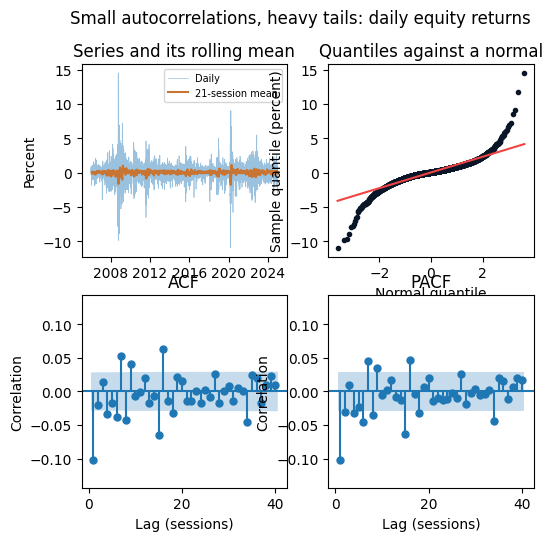

In [14]:
def plot_correlogram(series: pd.Series, claim: str, lags: int = 40):
    """Draw the four-panel correlogram: series with rolling mean, Q-Q, ACF, PACF."""
    series = series.dropna()
    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE["dashboard_2x2"])

    ax = axes[0, 0]
    ax.plot(series.index, series.values, linewidth=0.5, alpha=0.45, label="Daily")
    ax.plot(
        series.index,
        series.rolling(21).mean().values,
        linewidth=1.5,
        color=COLORS["copper"],
        label="21-session mean",
    )
    ax.set_title("Series and its rolling mean")
    ax.set_ylabel("Percent")
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    ax.legend(fontsize=7)

    ax = axes[0, 1]
    probplot(series, dist="norm", plot=ax)
    ax.get_lines()[0].set(color=COLORS["blue"], markerfacecolor=COLORS["blue"], markersize=3)
    ax.get_lines()[1].set_color(COLORS["negative"])
    ax.set_title("Quantiles against a normal")
    ax.set_xlabel("Normal quantile")
    ax.set_ylabel("Sample quantile (percent)")

    plot_acf(series, lags=lags, zero=False, ax=axes[1, 0])
    axes[1, 0].set_title("ACF")

    plot_pacf(series, lags=lags, zero=False, ax=axes[1, 1], method="ywm")
    axes[1, 1].set_title("PACF")

    # Both panels answer the same question and are read against each other, so they share
    # a limit set by the largest correlation either one draws.
    largest = max(
        np.abs(acf(series, nlags=lags)[1:]).max(),
        np.abs(pacf(series, nlags=lags, method="ywm")[1:]).max(),
    )
    for ax in axes[1]:
        ax.set_ylim(-1.4 * largest, 1.4 * largest)
        ax.set_xlabel("Lag (sessions)")
        ax.set_ylabel("Correlation")

    fig.suptitle(claim)
    return fig


fig = plot_correlogram(returns, "Small autocorrelations, heavy tails: daily equity returns")
show_with_alt(
    fig,
    "Four panels for SPY daily returns. Upper left: the daily series with a 21-session "
    "rolling mean that stays close to zero. Upper right: a quantile-quantile plot against "
    "the normal that bends away from the reference line at both ends. Lower left and "
    "right: the ACF and PACF, whose bars sit near zero at every lag with a handful "
    "reaching just past the confidence band.",
)

The rolling mean panel says the level of returns does not wander: it stays near zero
throughout, which is what a stationary series looks like. The quantile plot bends away
from the reference line at both ends, meaning the largest observed moves in each
direction are far larger than a normal distribution with this standard deviation would
produce. The ACF and PACF bars sit close to zero at every lag, so no single lag carries
much information about the next return; whether the small values are collectively
distinguishable from zero is what the Ljung-Box test below decides.

### Order suggestion from the library

`analyze_autocorrelation` reads the same ACF and PACF pattern and proposes the ARIMA
order the correlogram implies, which is the starting point `07_arima_features` fits.

In [15]:
acf_result = analyze_autocorrelation(returns.dropna().to_numpy())
print(f"Suggested ARIMA order (p, d, q): {acf_result.suggested_arima_order}")

Suggested ARIMA order (p, d, q): (2, 0, 1)


## Ljung-Box: are the autocorrelations jointly zero?

Reading individual ACF bars against a confidence band tests one lag at a time, and with
forty lags some will cross the band by chance. The **Ljung-Box** test pools the first
$m$ autocorrelations into a single statistic and tests them jointly, so it answers the
question the correlogram raises without paying for forty separate looks.

Four horizons are tested, chosen to span the intervals a daily strategy would care
about: one week, two weeks, one month and two months of sessions.

The test is then repeated on **squared** returns. Squaring discards the sign and keeps
the magnitude, so autocorrelation in squared returns means large moves are followed by
large moves regardless of direction. That is volatility clustering, and it is the
condition the GARCH models in `08_garch_volatility` are built to describe.

In [16]:
LJUNG_BOX_LAGS = [5, 10, 20, 40]

lb_returns = acorr_ljungbox(returns, lags=LJUNG_BOX_LAGS, return_df=True)
print(
    "Returns:",
    "autocorrelation detected"
    if (lb_returns["lb_pvalue"] < 0.05).any()
    else "no autocorrelation detected",
)
display(lb_returns)

lb_squared = acorr_ljungbox(returns**2, lags=LJUNG_BOX_LAGS, return_df=True)
print(
    "Squared returns:",
    "autocorrelation detected"
    if (lb_squared["lb_pvalue"] < 0.05).any()
    else "no autocorrelation detected",
)
display(lb_squared)

Returns: autocorrelation detected


,lb_stat,lb_pvalue
5,59.861450,1.298281e-11
10,97.384375,1.816669e-16
20,149.583327,7.552986e-22
40,179.554713,1.370718e-19


Squared returns: autocorrelation detected


,lb_stat,lb_pvalue
5,2397.204229,0.0
10,4095.462565,0.0
20,5971.342131,0.0
40,7427.791801,0.0


The two results answer different questions and are worth keeping apart. Rejection on
raw returns says the sign of the next move is not quite independent of the last few;
it says nothing about how large the dependence is, and over a sample this long a
very small autocorrelation is enough to reject. Rejection on squared returns says the
*size* of the next move is predictable from recent sizes, and that dependence is what
a volatility model is for.

## Turning the tests into features

Stationarity is not a fixed property of a series, and treating a single test over the
whole sample as settled throws that away. Refitting the same two tests on a window
that moves forward turns each one into a column: a series that passes for years and
then stops is exactly the event a model wants to know about, and the same construction
detects a cointegrating relationship weakening before the spread stops mean-reverting.

`ROLLING_WINDOW` sets how many sessions each test reads. At 252 it is about one trading
year, which is long enough for both tests to have power and short enough that a
regime lasting a few quarters is visible rather than averaged away. `ROLLING_STEP` sets
how often the tests are refitted: at 5 sessions that is once a trading week, which is
how often a weekly-rebalanced model would refresh the feature.

Each window ends at the session before the timestamp it is recorded under, so the value
stamped on a date is computable from data available on the previous close and can be
used as a feature for that date without look-ahead. The critical values are taken from
each test's own output rather than typed in, because both depend on the sample size and
ADF's also depends on the lag order `autolag` chose.

In [17]:
rolling_rows = []
skipped = 0

for end in range(ROLLING_WINDOW, len(returns), ROLLING_STEP):
    window = returns.iloc[end - ROLLING_WINDOW : end]
    try:
        adf_stat, adf_pval, _, _, adf_crit, _ = adfuller(window, autolag="AIC")
        kpss_stat, kpss_pval, _, kpss_crit = kpss(window, regression="c", nlags="auto")
    except ValueError:
        skipped += 1
        continue
    rolling_rows.append(
        {
            "timestamp": returns.index[end],
            "adf_statistic": adf_stat,
            "adf_pvalue": adf_pval,
            "adf_critical_5pct": adf_crit["5%"],
            "kpss_statistic": kpss_stat,
            "kpss_pvalue": kpss_pval,
            "kpss_critical_5pct": kpss_crit["5%"],
            "stationarity_regime": int(adf_pval < 0.05 and kpss_pval >= 0.05),
        }
    )

rolling_df = pd.DataFrame(rolling_rows).set_index("timestamp")
print(f"Windows computed: {len(rolling_df)}; windows a test refused: {skipped}")

Windows computed: 906; windows a test refused: 0


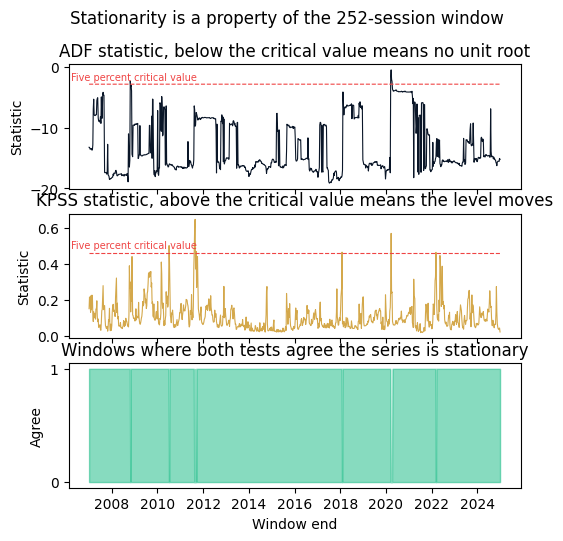

In [18]:
fig, axes = plt.subplots(3, 1, figsize=FIGSIZE["grid_3x2"], sharex=True)

for ax, column, critical, color, title in [
    (
        axes[0],
        "adf_statistic",
        "adf_critical_5pct",
        COLORS["blue"],
        "ADF statistic, below the critical value means no unit root",
    ),
    (
        axes[1],
        "kpss_statistic",
        "kpss_critical_5pct",
        COLORS["amber"],
        "KPSS statistic, above the critical value means the level moves",
    ),
]:
    ax.plot(rolling_df.index, rolling_df[column], linewidth=0.8, color=color)
    ax.plot(
        rolling_df.index,
        rolling_df[critical],
        color=COLORS["negative"],
        linestyle="--",
        linewidth=0.8,
    )
    # The critical value is labelled on the line rather than in a legend, which on these
    # panels lands on the data whichever corner it is given.
    ax.annotate(
        "Five percent critical value",
        xy=(0.005, rolling_df[critical].median()),
        xycoords=("axes fraction", "data"),
        xytext=(0, 3),
        textcoords="offset points",
        fontsize=7,
        color=COLORS["negative"],
    )
    ax.set_title(title)
    ax.set_ylabel("Statistic")

ax = axes[2]
ax.fill_between(
    rolling_df.index, 0, rolling_df["stationarity_regime"], alpha=0.5, color=COLORS["positive"]
)
ax.set_title("Windows where both tests agree the series is stationary")
ax.set_ylabel("Agree")
ax.set_yticks([0, 1])
ax.set_xlabel("Window end")

fig.suptitle(f"Stationarity is a property of the {ROLLING_WINDOW}-session window")
show_with_alt(
    fig,
    f"Three stacked panels over the sample, one point per {ROLLING_STEP} sessions. Top: "
    "the rolling ADF statistic against its five percent critical value, staying well "
    "below it for most of the sample. Middle: the rolling KPSS statistic against its "
    "five percent critical value, crossing above it in places. Bottom: a filled band "
    "marking the windows in which both tests agree the returns are stationary, with gaps "
    "where they disagree.",
)

## Distribution: what shape are the returns

Stationarity and autocorrelation describe how a series moves through time. The shape of
its distribution at a point in time is a separate question, and it decides different
things: how far into the tail a risk measure has to reach, whether a directional bet is
symmetric, and whether a model that assumes normal errors will understate extremes.

`analyze_distribution` reports the first four moments with the **Jarque-Bera** test,
which combines skewness and kurtosis into one test of normality. Note the convention:
**excess** kurtosis is measured against the normal distribution, so a normal has excess
kurtosis of zero and a positive value means more probability in the tails than a normal
with the same standard deviation.

In [19]:
dist_result = analyze_distribution(returns.dropna().to_numpy())
moments = dist_result.moments_result
print(f"Mean daily return (percent):     {moments.mean:.4f}")
print(f"Standard deviation (percent):    {moments.std:.4f}")
print(f"Skewness:                        {moments.skewness:.4f}")
print(f"Excess kurtosis (normal is 0):   {moments.excess_kurtosis:.4f}")
print(f"Jarque-Bera p-value:             {dist_result.jarque_bera_result.p_value:.6f}")
print(f"Consistent with a normal:        {dist_result.is_normal}")

Mean daily return (percent):     0.0470
Standard deviation (percent):    1.2210
Skewness:                        -0.0810
Excess kurtosis (normal is 0):   14.5643
Jarque-Bera p-value:             0.000000
Consistent with a normal:        False


Excess kurtosis this far above zero is why a model that assumes normal errors
understates how often a large move happens, and why a value-at-risk figure read off a
normal quantile is not the one to use. It does not disappear once volatility is
modelled: `08_garch_volatility` fits GARCH with normal innovations and then plots the
standardized residuals against a normal, where the tails are still too heavy. Heavier
innovation distributions such as Student-t are the response to what is left over.

## ARCH effects: the formal test

The Ljung-Box result on squared returns pointed at volatility clustering. The ARCH-LM
test states the same question as a regression: it regresses squared returns on their
own lags and tests whether those lags jointly explain anything. Its null is that they
do not, so rejecting it says the variance of the next return depends on recent squared
returns. That condition is what a **conditionally heteroscedastic** model such as GARCH
is built on, and a model assuming constant variance has nothing to say about it.

In [20]:
arch_result = arch_lm_test(returns.dropna().to_numpy())
print(f"ARCH-LM statistic:  {arch_result.test_statistic:.4f}")
print(f"P-value:            {arch_result.p_value:.6f}")
print(f"ARCH effects:       {arch_result.has_arch_effects}")

ARCH-LM statistic:  1478.2363
P-value:            0.000000
ARCH effects:       True


## The features this notebook produces

| Column | Computed from | Recomputed |
|---|---|---|
| `adf_statistic` | ADF over the trailing window | every `ROLLING_STEP` sessions |
| `adf_pvalue` | ADF over the trailing window | every `ROLLING_STEP` sessions |
| `kpss_statistic` | KPSS over the trailing window | every `ROLLING_STEP` sessions |
| `kpss_pvalue` | KPSS over the trailing window | every `ROLLING_STEP` sessions |
| `stationarity_regime` | the two tests read jointly | every `ROLLING_STEP` sessions |

Each is held in `rolling_df` and stamped on the session after its window closes, so a
model reading it on that date reads only what was available beforehand.

## Key takeaways

1. **Look before testing.** The four-panel view raises the questions the tests answer,
   and it takes one cell.
2. **Two tests, opposite nulls.** ADF alone cannot distinguish "stationary" from "the
   sample does not settle it", and KPSS alone cannot either. Read jointly they separate
   four cases, and `analyze_stationarity` returns the same reading with a third test.
3. **Differencing is the standard fix and it is not free.** Prices are not stationary
   and their returns are, but first differencing discards the level information
   entirely; `03_fractional_differencing` keeps as much of it as stationarity allows.
4. **Test the squares, not only the series.** Autocorrelation in squared returns is
   what makes volatility the most forecastable part of a return series, and it is what
   `08_garch_volatility` models.
5. **A diagnostic recomputed on a rolling window is a feature.** The same two tests
   that answer once over the full sample give a column that changes when the
   series does, provided each window is stamped on a date it could have been computed
   for.

**Known limitations.** Both tests assume a single generating process over the window
they read, so a break inside the window shows up as a rejection without saying where it
happened; `02_structural_breaks` locates it. The rolling loop refits on overlapping
windows, so consecutive values of every column above are strongly dependent and their
variation is not evidence about independent draws. And the window length trades power
against responsiveness: a shorter window notices a change sooner and rejects less often
on a series that has genuinely stopped being stationary.

**Next**: `02_structural_breaks` for locating a break, and
`03_fractional_differencing` for reaching stationarity without discarding the level.